# Wooldridge Multiple OLS Linear Regression using Python
**Author:**
Brahim Zirari <br>
**Version:**
Python 3.13.5 <br>
**Topic:** <br>
* This notebook contains an example about simple & Multiple linear regression model as well as diagnostics from Introductory Econometrics: A Modern Approach, 5e by Jeffrey M. Wooldridge. <br>
**Source** Book. 
<a href = "https://www.amazon.com/Introductory-Econometrics-Modern-Approach-Economics/dp/1111531048" > Click here </a>

In [ ]:
pip install wooldridge

In [1]:
import wooldridge as wl

# Import Important Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
#to draw multiple plots
%matplotlib inline    

# Now, install and load the wooldridge package and lets get started!

In [3]:
#!pip install wooldridge
import wooldridge as wl

In [4]:
print(help(wl))

Help on package wooldridge:

NAME
    wooldridge - Github page: https://github.com/spring-haru/wooldridge

PACKAGE CONTENTS
    datasets (package)
    description (package)
    load_data

FUNCTIONS
    data(name=None, description=False)

    dataWoo(name=None, description=False)

DATA
    __all__ = ['data', 'dataWoo']
    __copyright__ = 'Copyright (c) 2025 Tetsu Haruyama'

VERSION
    0.5.0

AUTHOR
    Tetsu Haruyama

FILE
    c:\users\brahim\appdata\local\programs\python\python314\lib\site-packages\wooldridge\__init__.py


None


Load the wage1 data and check out the documentation.

In [5]:
wl.dataWoo(name = "wage1", description= True)

name of dataset: wage1
no of variables: 24
no of observations: 526

+----------+---------------------------------+
| variable | label                           |
+----------+---------------------------------+
| wage     | average hourly earnings         |
| educ     | years of education              |
| exper    | years potential experience      |
| tenure   | years with current employer     |
| nonwhite | =1 if nonwhite                  |
| female   | =1 if female                    |
| married  | =1 if married                   |
| numdep   | number of dependents            |
| smsa     | =1 if live in SMSA              |
| northcen | =1 if live in north central U.S |
| south    | =1 if live in southern region   |
| west     | =1 if live in western region    |
| construc | =1 if work in construc. indus.  |
| ndurman  | =1 if in nondur. manuf. indus.  |
| trcommpu | =1 if in trans, commun, pub ut  |
| trade    | =1 if in wholesale or retail    |
| services | =1 if in services indus.  

In [6]:
df = wl.dataWoo(name = "wage1")
print(df.head())

   wage  educ  exper  tenure  nonwhite  female  married  numdep  smsa  \
0  3.10    11      2       0         0       1        0       2     1   
1  3.24    12     22       2         0       1        1       3     1   
2  3.00    11      2       0         0       0        0       2     0   
3  6.00     8     44      28         0       0        1       0     1   
4  5.30    12      7       2         0       0        1       1     0   

   northcen  ...  trcommpu  trade  services  profserv  profocc  clerocc  \
0         0  ...         0      0         0         0        0        0   
1         0  ...         0      0         1         0        0        0   
2         0  ...         0      1         0         0        0        0   
3         0  ...         0      0         0         0        0        1   
4         0  ...         0      0         0         0        0        0   

   servocc     lwage  expersq  tenursq  
0        0  1.131402        4        0  
1        1  1.175573      48

### Import statsmodels

In [7]:
import statsmodels.formula.api as sm

**Exploratory Data Analysis (EDA)**

Estimate kernel density:

<Axes: ylabel='Density'>

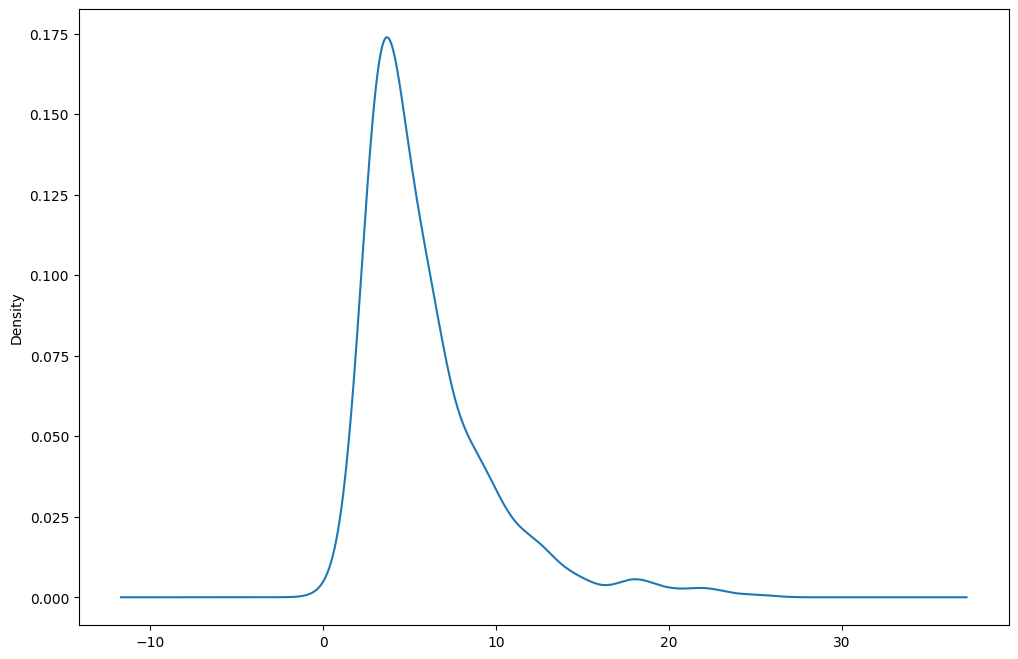

In [8]:
df["wage"].plot(kind = "kde", figsize = (12,8))

Plotting scatter plot between wage and educ

In [9]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [9]:
#Skewness and Kurtosis
from scipy.stats import skew, kurtosis
print("Skew coef :", skew(df["wage"])) #compared to 3
print("Kurtosis coef:", kurtosis(df["wage"])) #compared to 0

Skew coef : 2.0073250401421583
Kurtosis coef: 4.970082831531241


In [10]:
from scipy.stats import jarque_bera
jarque_bera(df["wage"])

SignificanceResult(statistic=np.float64(894.6194547420355), pvalue=np.float64(5.443192595085401e-195))

Descreptive statistics:

In [11]:
df.describe()

,wage,educ,exper,tenure,nonwhite,female,married,numdep,smsa,northcen,...,trcommpu,trade,services,profserv,profocc,clerocc,servocc,lwage,expersq,tenursq
count,526.000000,526.000000,526.00000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,...,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000
mean,5.896103,12.562738,17.01711,5.104563,0.102662,0.479087,0.608365,1.043726,0.722433,0.250951,...,0.043726,0.287072,0.100760,0.258555,0.366920,0.167300,0.140684,1.623268,473.435361,78.150190
std,3.693086,2.769022,13.57216,7.224462,0.303805,0.500038,0.488580,1.261891,0.448225,0.433973,...,0.204680,0.452826,0.301298,0.438257,0.482423,0.373599,0.348027,0.531538,616.044772,199.434664
min,0.530000,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.634878,1.000000,0.000000
25%,3.330000,12.000000,5.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.202972,25.000000,0.000000
50%,4.650000,12.000000,13.50000,2.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.536867,182.500000,4.000000
75%,6.880000,14.000000,26.00000,7.000000,0.000000,1.000000,1.000000,2.000000,1.000000,0.750000,...,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.928619,676.000000,49.000000
max,24.980000,18.000000,51.00000,44.000000,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.218076,2601.000000,1936.000000


Plotting  Boxplot:

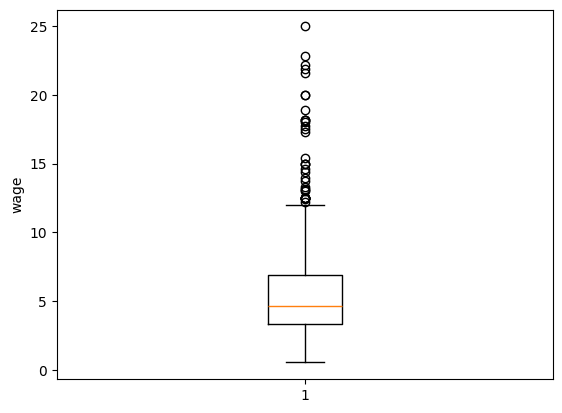

In [12]:
plt.boxplot(df["wage"], vert=True)
plt.ylabel("wage")
plt.show()

# Multiple Regression Analysis

In [13]:
df.columns

Index(['wage', 'educ', 'exper', 'tenure', 'nonwhite', 'female', 'married',
       'numdep', 'smsa', 'northcen', 'south', 'west', 'construc', 'ndurman',
       'trcommpu', 'trade', 'services', 'profserv', 'profocc', 'clerocc',
       'servocc', 'lwage', 'expersq', 'tenursq'],
      dtype='str')

In [14]:
wage = df["wage"]
educ = df["educ"]
exper = df["exper"]
tenure = df["tenure"]

In [15]:
model = sm.ols("wage~educ+exper+tenure", data = df)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.306
Model:                            OLS   Adj. R-squared:                  0.302
Method:                 Least Squares   F-statistic:                     76.87
Date:                Mon, 02 Mar 2026   Prob (F-statistic):           3.41e-41
Time:                        11:30:38   Log-Likelihood:                -1336.8
No. Observations:                 526   AIC:                             2682.
Df Residuals:                     522   BIC:                             2699.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.8727      0.729     -3.941      0.0

In [18]:
#results.summary()
#results.params
#results.fittedvalues y_hat
#results.resid  

# Regression Diagnostics

## Heteroscedasticity Tests

1. Breusch-Pagan Lagrange Multiplier test

In [19]:
from statsmodels.stats.diagnostic import het_breuschpagan

name = ["breuschpagan statistic", "p-value"]
test = het_breuschpagan(results.resid, results.model.exog)
list(zip(name, test))

[('breuschpagan statistic', np.float64(43.095617434641106)),
 ('p-value', np.float64(2.3486063795662544e-09))]

2. Lagrange Multiplier Heteroscedasticity Test by White

In [20]:
from statsmodels.stats.diagnostic import het_white

name = ["White  statistic", "p-value"]
test = het_white(results.resid, results.model.exog)
list(zip(name, test))

[('White  statistic', np.float64(63.960009051619856)),
 ('p-value', np.float64(2.2976863558025742e-10))]

# Autocorrelation Tests

1. Breusch-Godfrey Lagrange Multiplier tests for residual autocorrelation.

In [21]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey 
name = ["breusch_godfrey statistic", "p-value"]

test = acorr_breusch_godfrey(results, nlags=None, store=False)
list(zip(name, test))

[('breusch_godfrey statistic', np.float64(10.735179370055098)),
 ('p-value', np.float64(0.37851878667428757))]

# Multicollinearity Tests

In [20]:
df.head()
df.iloc[0:4,1:4]

,educ,exper,tenure
0,11,2,0
1,12,22,2
2,11,2,0
3,8,44,28


1. Correlation matrix

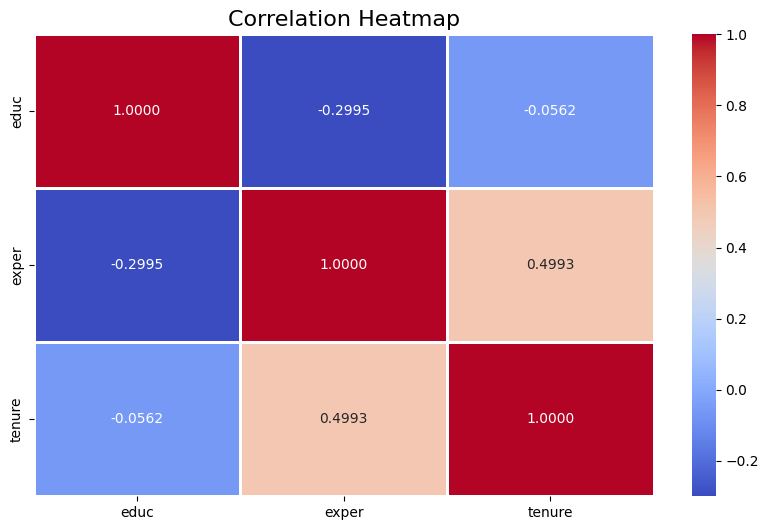

In [25]:
import seaborn as sns
df_mlr = df.iloc[:, 0:4]
df_mlr_without_y = df_mlr.drop("wage", axis=1)
# Correlation matrix
correlation_matrix = df_mlr_without_y.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a heatmap for the correlation matrix
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".4f", linewidths=0.8)

# Title for the heatmap
plt.title("Correlation Heatmap", fontsize=16)

# Show the heatmap
plt.show()

In [17]:
#df.corr()
#df_mlr = df.iloc[:,[0,1,2,3]]
#print(df_mlr)
#df_mlr.corr()
print(df_mlr_without_y)

     educ  exper  tenure
0      11      2       0
1      12     22       2
2      11      2       0
3       8     44      28
4      12      7       2
..    ...    ...     ...
521    16     14       2
522    10      2       0
523    15     13      18
524    16      5       1
525    14      5       4

[526 rows x 3 columns]


2. Variance Inflation Fctor VIF

In [18]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each numerical feature
vif_data = pd.DataFrame()
vif_data["feature"] = df_mlr_without_y.columns

# Calculate VIF and round to 4 decimal places
print(df_mlr_without_y.shape[1])
vif_data["VIF"] = [round(variance_inflation_factor(df_mlr_without_y.values, i), 4) for i in range(df_mlr_without_y.shape[1])]
# Sort VIF values in descending order
#vif_data = vif_data.sort_values(by="VIF", ascending=False)

# Display the VIF DataFrame
print(vif_data)

3
  feature     VIF
0    educ  2.1160
1   exper  2.9207
2  tenure  2.0075


# Normality and Distribution Tests

1. Jarque Bera Test

In [26]:
from scipy.stats import jarque_bera
name = ["Jarque-Bera test", "Chi^2 two-tail prob."]
test = jarque_bera(results.resid)
list(zip(name, test))

[('Jarque-Bera test', np.float64(650.8075112915261)),
 ('Chi^2 two-tail prob.', np.float64(4.774682881096291e-142))]

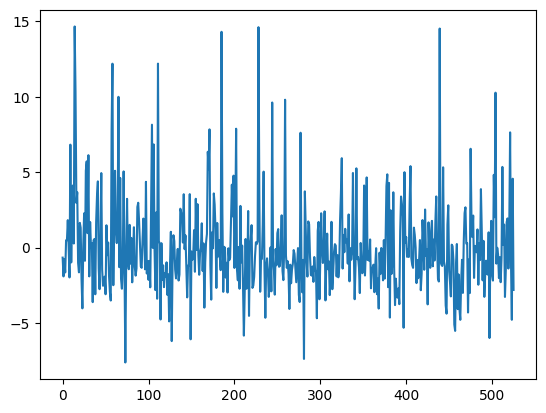

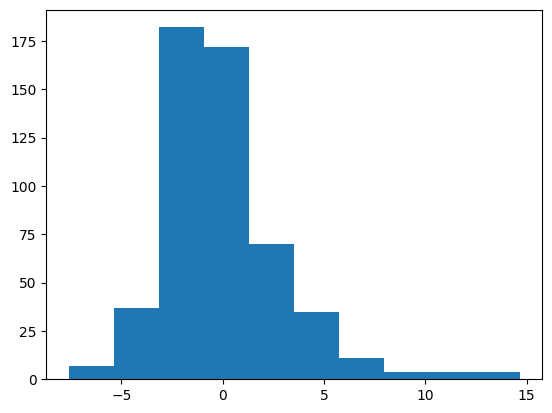

In [27]:
plt.plot(results.resid)
plt.show()
plt.hist(results.resid)
plt.show()